# **Sentimental Analysis**

# **Importing Libraries**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset

**Loading Dataset from Hugging Face**

In [2]:
data = load_dataset('google-research-datasets/go_emotions')

**Extracting training and testing data**

In [3]:
train_df = data['train']
test_df = data['test']

In [4]:
train_df

Dataset({
    features: ['text', 'labels', 'id'],
    num_rows: 43410
})

In [5]:
train_df[0]

{'text': "My favourite food is anything I didn't have to cook myself.",
 'labels': [27],
 'id': 'eebbqej'}

In [6]:
train_df = train_df.to_pandas()
test_df = test_df.to_pandas()

In [7]:
train_df

,text,labels,id
0,My favourite food is anything I didn't have to...,[27],eebbqej
1,"Now if he does off himself, everyone will thin...",[27],ed00q6i
2,WHY THE FUCK IS BAYLESS ISOING,[2],eezlygj
3,To make her feel threatened,[14],ed7ypvh
4,Dirty Southern Wankers,[3],ed0bdzj
...,...,...,...
43405,Added you mate well I’ve just got the bow and ...,[18],edsb738
43406,Always thought that was funny but is it a refe...,[6],ee7fdou
43407,What are you talking about? Anything bad that ...,[3],efgbhks
43408,"More like a baptism, with sexy results!",[13],ed1naf8


**Dropping Id column**

In [8]:
train_df = train_df.drop('id',axis=1)
test_df = test_df.drop('id',axis=1)

In [9]:
train_df.head()

,text,labels
0,My favourite food is anything I didn't have to...,[27]
1,"Now if he does off himself, everyone will thin...",[27]
2,WHY THE FUCK IS BAYLESS ISOING,[2]
3,To make her feel threatened,[14]
4,Dirty Southern Wankers,[3]


In [10]:
test_df.head()

,text,labels
0,I’m really sorry about your situation :( Altho...,[25]
1,It's wonderful because it's awful. At not with.,[0]
2,"Kings fan here, good luck to you guys! Will be...",[13]
3,"I didn't know that, thank you for teaching me ...",[15]
4,They got bored from haunting earth for thousan...,[27]


**Emotion Category**

In [11]:
data['train'].features['labels'].feature.names

['admiration',
 'amusement',
 'anger',
 'annoyance',
 'approval',
 'caring',
 'confusion',
 'curiosity',
 'desire',
 'disappointment',
 'disapproval',
 'disgust',
 'embarrassment',
 'excitement',
 'fear',
 'gratitude',
 'grief',
 'joy',
 'love',
 'nervousness',
 'optimism',
 'pride',
 'realization',
 'relief',
 'remorse',
 'sadness',
 'surprise',
 'neutral']

In [12]:
mapping = dict(enumerate(data['train'].features['labels'].feature.names))

In [13]:
mapping

{0: 'admiration',
 1: 'amusement',
 2: 'anger',
 3: 'annoyance',
 4: 'approval',
 5: 'caring',
 6: 'confusion',
 7: 'curiosity',
 8: 'desire',
 9: 'disappointment',
 10: 'disapproval',
 11: 'disgust',
 12: 'embarrassment',
 13: 'excitement',
 14: 'fear',
 15: 'gratitude',
 16: 'grief',
 17: 'joy',
 18: 'love',
 19: 'nervousness',
 20: 'optimism',
 21: 'pride',
 22: 'realization',
 23: 'relief',
 24: 'remorse',
 25: 'sadness',
 26: 'surprise',
 27: 'neutral'}

In [14]:
train_df['label_category'] = train_df['labels'].apply(lambda x: [mapping[i]for i in x])
test_df['label_category'] = test_df['labels'].apply(lambda x: [mapping[i]for i in x])
train_df.head(10)

,text,labels,label_category
0,My favourite food is anything I didn't have to...,[27],[neutral]
1,"Now if he does off himself, everyone will thin...",[27],[neutral]
2,WHY THE FUCK IS BAYLESS ISOING,[2],[anger]
3,To make her feel threatened,[14],[fear]
4,Dirty Southern Wankers,[3],[annoyance]
5,OmG pEyToN iSn'T gOoD eNoUgH tO hElP uS iN tHe...,[26],[surprise]
6,Yes I heard abt the f bombs! That has to be wh...,[15],[gratitude]
7,We need more boards and to create a bit more s...,"[8, 20]","[desire, optimism]"
8,Damn youtube and outrage drama is super lucrat...,[0],[admiration]
9,It might be linked to the trust factor of your...,[27],[neutral]


In [15]:
train_df.isna().sum()

,0
text,0
labels,0
label_category,0


In [16]:
train_df['text'].duplicated().sum()

np.int64(183)

In [17]:
train_df.drop_duplicates(subset=['text'])['text'].duplicated().sum()

np.int64(0)

In [18]:
train_df = train_df.drop_duplicates(subset=['text'])

In [19]:
train_df.head()

,text,labels,label_category
0,My favourite food is anything I didn't have to...,[27],[neutral]
1,"Now if he does off himself, everyone will thin...",[27],[neutral]
2,WHY THE FUCK IS BAYLESS ISOING,[2],[anger]
3,To make her feel threatened,[14],[fear]
4,Dirty Southern Wankers,[3],[annoyance]


**Visualizing count of differet classes in Training Dataset**

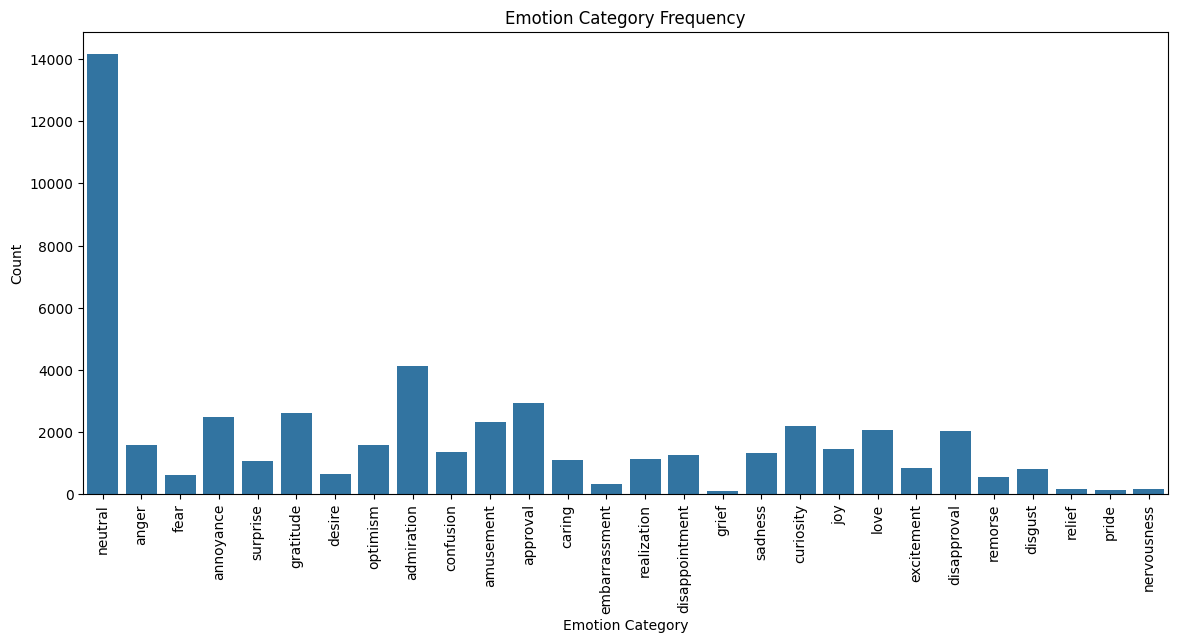

In [20]:
plt.figure(figsize=(14, 6))
sns.countplot(x=train_df['label_category'].explode())
plt.xticks(rotation=90)
plt.xlabel('Emotion Category')
plt.ylabel('Count')
plt.title('Emotion Category Frequency')
plt.show()

In [21]:
from sklearn.preprocessing import MultiLabelBinarizer

In [22]:
mlb = MultiLabelBinarizer()
train_labels = mlb.fit_transform(train_df['labels'])
test_labels = mlb.transform(test_df['labels'])
num_classes = train_labels.shape[1]
print(f'train_labels : {train_labels}\nTest Labels : {test_labels}\nNum Of classes : {num_classes}')

train_labels : [[0 0 0 ... 0 0 1]
 [0 0 0 ... 0 0 1]
 [0 0 1 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]
Test Labels : [[0 0 0 ... 1 0 0]
 [1 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 1]
 [1 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 1]]
Num Of classes : 28


In [23]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

In [40]:
max_words = 16000
max_len = 70

tokenizer = Tokenizer(num_words=max_words, oov_token='<OOV>')
tokenizer.fit_on_texts(train_df['text'])

train_sequence = tokenizer.texts_to_sequences(train_df['text'])
test_sequence = tokenizer.texts_to_sequences(test_df['text'])

padded_train_sequence = pad_sequences(train_sequence, maxlen=max_len, padding='post', truncating='post')
padded_test_sequence = pad_sequences(test_sequence, maxlen=max_len, padding='post', truncating='post')

print(f"Vocabulary Size: {len(tokenizer.word_index)}")
print(f"Train Sequences Shape: {padded_train_sequence.shape}")
print(f"Train Labels Matrix Shape: {train_labels.shape}")


Vocabulary Size: 28208
Train Sequences Shape: (43227, 70)
Train Labels Matrix Shape: (43227, 28)


**Handling Calss Imbalance**

In [25]:
total_samples = len(train_labels)
pos_counts = train_labels.sum(axis=0)
weights = total_samples / (2.0 * pos_counts)
class_weight_dict = {i: weight for i, weight in enumerate(weights)}

In [26]:
from tensorflow.keras.callbacks import EarlyStopping
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

# **Bidirectional GRU model implementation**

In [28]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, GRU, Dense, Dropout, Bidirectional
import tensorflow as tf
model_bigru = Sequential([
    Embedding(input_dim=max_words, output_dim=300, input_length=max_len),
    Bidirectional(GRU(128, return_sequences=True)),
    Dropout(0.5),
    Bidirectional(GRU(64)),
    Dropout(0.5),
    Dense(num_classes, activation='sigmoid')
])

model_bigru.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy', tf.keras.metrics.AUC(name='auc')]
)

model_performance = model_bigru.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_test_sequence, test_labels),
    epochs=20,
    batch_size=128,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

loss, accuracy, auc = model_bigru.evaluate(padded_test_sequence, test_labels)
print(f"BiGRU Loss: {loss:.4f}")
print(f"BiGRU Accuracy: {accuracy:.4f}")
print(f"BiGRU AUC: {auc:.4f}")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Epoch 1/20
338/338 ━━━━━━━━━━━━━━━━━━━━ 46s 58ms/step - accuracy: 0.1030 - auc: 0.6095 - loss: 2.2287 - val_accuracy: 0.3074 - val_auc: 0.7923 - val_loss: 0.1488
Epoch 2/20
338/338 ━━━━━━━━━━━━━━━━━━━━ 13s 32ms/step - accuracy: 0.2802 - auc: 0.7944 - loss: 1.7122 - val_accuracy: 0.4596 - val_auc: 0.8788 - val_loss: 0.1236
Epoch 3/20
338/338 ━━━━━━━━━━━━━━━━━━━━ 10s 30ms/step - accuracy: 0.4104 - auc: 0.8746 - loss: 1.4146 - val_accuracy: 0.4544 - val_auc: 0.8959 - val_loss: 0.1148
Epoch 4/20
338/338 ━━━━━━━━━━━━━━━━━━━━ 10s 31ms/step - accuracy: 0.4608 - auc: 0.9060 - loss: 1.2009 - val_accuracy: 0.4371 - val_auc: 0.9061 - val_loss: 0.1121
Epoch 5/20
338/338 ━━━━━━━━━━━━━━━━━━━━ 10s 31ms/step - accuracy: 0.5036 - auc: 0.9253 - loss: 1.0375 - val_accuracy: 0.4019 - val_auc: 0.9036 - val_loss: 0.1139
Epoch 6/20
338/338 ━━━━━━━━━━━━━━━━━━━━ 10s 31ms/step - accuracy: 0.5440 - auc: 0.9373 - loss: 0.9145 - val_accuracy: 0.4063 - val_auc: 0.8997 - val_loss: 0.1171
Epoch 7/20
338/338 ━━━━━━━━━

In [29]:
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    hamming_loss,
    accuracy_score,
    classification_report,
    roc_auc_score
)

y_prob = model_bigru.predict(padded_test_sequence)
threshold = 0.5
y_pred = (y_prob >= threshold).astype(int)
y_true = np.asarray(test_labels).astype(int)

print("Micro F1:",
      f1_score(y_true, y_pred, average="micro", zero_division=0))

print("Macro F1:",
      f1_score(y_true, y_pred, average="macro", zero_division=0))

print("Weighted F1:",
      f1_score(y_true, y_pred, average="weighted", zero_division=0))

print("Micro Precision:",
      precision_score(y_true, y_pred, average="micro", zero_division=0))

print("Micro Recall:",
      recall_score(y_true, y_pred, average="micro", zero_division=0))

print("Hamming Loss:",
      hamming_loss(y_true, y_pred))

print("Exact Match Accuracy:",
      accuracy_score(y_true, y_pred))

try:
    print("Macro ROC-AUC:",
          roc_auc_score(y_true, y_prob, average="macro"))
except ValueError as e:
    print("ROC-AUC could not be calculated:", e)

170/170 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step
Micro F1: 0.3394243401409292
Macro F1: 0.3374533605339481
Weighted F1: 0.2620303391137483
Micro Precision: 0.6952054794520548
Micro Recall: 0.22452204139674514
Hamming Loss: 0.03639869435889336
Exact Match Accuracy: 0.20066334991708126
Macro ROC-AUC: 0.8660849671751742


**Results are not satisfactory**

In [30]:
thresholds = [0.3,0.4,0.6]
best_thresh = 0.5
best_f1 = 0

for t in thresholds:
    preds = (y_prob >= t).astype(int)
    score = f1_score(y_true, preds, average="micro", zero_division=0)
    if score > best_f1:
        best_f1 = score
        best_thresh = t

print(f"Best Global Threshold: {best_thresh:.2f} | Micro F1: {best_f1:.4f}")

Best Global Threshold: 0.30 | Micro F1: 0.3944


In [31]:
t=0.02
preds = (y_prob >= t).astype(int)
lscore = f1_score(y_true, preds, average="micro", zero_division=0)
lscore

0.2154094847841206

**Results are still not great 0.4 F1 score might not be the worst for a 28 multilabel class problem but we need better results**

# **Bert Model**

In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments


In [ ]:
model_name = "monologg/bert-base-cased-goemotions-original"
tokenizer = AutoTokenizer.from_pretrained(model_name)

In [ ]:
def tokenize_function(examples):
    return tokenizer(examples["text"], padding="max_length", truncation=True, max_length=70)

In [ ]:
from datasets import Dataset
train_ds = Dataset.from_pandas(train_df[['text', 'labels']])
test_ds = Dataset.from_pandas(test_df[['text', 'labels']])

In [ ]:
train_ds

In [ ]:
train_ds[0]

In [ ]:
def format_labels(example):
    labels_vec = [0.0] * 28
    for l in example['labels']:
        labels_vec[l] = 1.0
    example['labels'] = labels_vec
    return example

In [ ]:
train_ds = train_ds.map(format_labels).map(tokenize_function, batched=True)
test_ds = test_ds.map(format_labels).map(tokenize_function, batched=True)

In [ ]:
model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=28,
    problem_type="multi_label_classification"
)

In [ ]:
training_args = TrainingArguments(
    output_dir="./results",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    gradient_accumulation_steps=2,
    num_train_epochs=3,
    weight_decay=0.01,
    fp16=True
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=test_ds,
)


In [ ]:
import gc
gc.collect()
torch.cuda.empty_cache()

In [ ]:
#trainer.train()

**Collab unable to train model because of high computation power required for training**

In [ ]:
from transformers import DataCollatorWithPadding

In [ ]:
model_name = "distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(model_name)

In [ ]:
def preprocess_function(examples):
    tokenized = tokenizer(examples["text"], truncation=True, max_length=70)
    labels_batch = []
    for label_list in examples["labels"]:
        vec = [0.0] * 28
        for l in label_list:
            vec[l] = 1.0
        labels_batch.append(vec)

    tokenized["labels"] = labels_batch
    return tokenized

In [ ]:
train_ds = train_ds.map(preprocess_function, batched=True, remove_columns=['text'])
test_ds = test_ds.map(preprocess_function, batched=True, remove_columns=['text'])

In [ ]:
model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=28,
    problem_type="multi_label_classification"
)

In [ ]:
training_args = TrainingArguments(
    output_dir="./distilbert_results",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=3e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=16,
    gradient_accumulation_steps=4,
    num_train_epochs=3,
    weight_decay=0.01,
    fp16=True,
    dataloader_num_workers=0,
    logging_steps=100
)

In [ ]:
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

In [ ]:
gc.collect()
torch.cuda.empty_cache()

In [ ]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=test_ds,
    data_collator=data_collator,
)

In [ ]:
# trainer.train()

**This model still not able to train due to lack of computational power**

In [32]:
best_per_class_thresholds = []
for c in range(y_true.shape[1]):
    best_c_thresh = 0.5
    best_c_f1 = 0
    for t in np.arange(0.05, 0.50, 0.02):
        preds_c = (y_prob[:, c] >= t).astype(int)
        f1_c = f1_score(y_true[:, c], preds_c, zero_division=0)
        if f1_c > best_c_f1:
            best_c_f1 = f1_c
            best_c_thresh = t
    best_per_class_thresholds.append(best_c_thresh)


y_pred_custom = np.zeros_like(y_prob)
for c, t in enumerate(best_per_class_thresholds):
    y_pred_custom[:, c] = (y_prob[:, c] >= t).astype(int)

print("BiGRU Micro F1 (Default thresh = 0.5):", f1_score(y_true, (y_prob >= 0.5).astype(int), average="micro", zero_division=0))
print("BiGRU Micro F1 (Optimized Per-Class):", f1_score(y_true, y_pred_custom, average="micro", zero_division=0))

BiGRU Micro F1 (Default thresh = 0.5): 0.3394243401409292
BiGRU Micro F1 (Optimized Per-Class): 0.514273978229616


In [33]:
print("Micro Precision:", precision_score(y_true, y_pred_custom, average="micro", zero_division=0))
print("Micro Recall:   ", recall_score(y_true, y_pred_custom, average="micro", zero_division=0))
print("Micro F1 Score: ", f1_score(y_true, y_pred_custom, average="micro", zero_division=0))
print("Macro F1 Score: ", f1_score(y_true, y_pred_custom, average="macro", zero_division=0))
print("Hamming Loss:   ", hamming_loss(y_true, y_pred_custom))
print("Exact Match Acc:", accuracy_score(y_true, y_pred_custom))

Micro Precision: 0.45373278569702824
Micro Recall:    0.5934586822562806
Micro F1 Score:  0.514273978229616
Macro F1 Score:  0.45637960041991704
Hamming Loss:    0.04669114743741609
Exact Match Acc: 0.31453841901603097


In [43]:
import pickle
model_bigru.save("bigru_goemotions_model.keras")
artifacts = {
    "tokenizer": tokenizer,
    "thresholds": best_per_class_thresholds,
    "mapping": mapping,
    "max_len": max_len
}

with open("model_artifacts.pkl", "wb") as f:
    pickle.dump(artifacts, f)

print("Model and artifacts successfully saved!")

Model and artifacts successfully saved!


In [37]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

keras_tokenizer = Tokenizer(num_words=16000, oov_token='<OOV>')
keras_tokenizer.fit_on_texts(train_df['text'])

In [41]:
def predict_emotion(text, model, tokenizer, thresholds, mapping, max_len=70):
    seq = tokenizer.texts_to_sequences([text])
    padded = pad_sequences(seq, maxlen=max_len, padding='post', truncating='post')
    probs = model.predict(padded, verbose=0)[0]

    predicted_emotions = []
    for c, prob in enumerate(probs):
        if prob >= thresholds[c]:
            predicted_emotions.append((mapping[c], round(float(prob), 4)))

    if not predicted_emotions:
        top_idx = np.argmax(probs)
        predicted_emotions.append((mapping[top_idx], round(float(probs[top_idx]), 4)))

    return predicted_emotions

In [42]:
sample_text = "I am so glad of how well this model performed today!"
predictions = predict_emotion(sample_text, model_bigru, keras_tokenizer, best_per_class_thresholds, mapping)

print(f"Text: '{sample_text}'")
print(f"Predicted Emotions: {predictions}")

Text: 'I am so glad of how well this model performed today!'
Predicted Emotions: [('relief', 0.3647)]


In [46]:
text = "Man, you did well today, I am proud of you"
prediction = predict_emotion(text, model_bigru, keras_tokenizer, best_per_class_thresholds, mapping)

print(f"Text: '{text}'")
print(f"Predicted Emotions: {prediction}")

Text: 'Man, you did well today, I am proud of you'
Predicted Emotions: [('pride', 0.6432), ('neutral', 0.1412)]


In [44]:
from google.colab import files

files.download("bigru_goemotions_model.keras")
files.download("model_artifacts.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>